In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(pistack_dir)
df = pd.read_csv('pi_stack_EDA.csv', index_col=0)
# df = raw_df.query('TOTAL < 0')
df.shape

(924, 40)

In [2]:
print(len(df.query('TOTAL > 0'))) 
print(len(df.query('TOTAL < 0')))

10
914


In [3]:
labels = ['Parallel', 'T-Shaped']

def split_type(df):
    dfList = []
    dfList.append(df.query('type == "P" & TOTAL < 0'))
    dfList.append(df.query('type == "T" & TOTAL < 0'))
    return dfList

In [4]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Parallel T-Shaped Comparison

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_18265/668042241.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


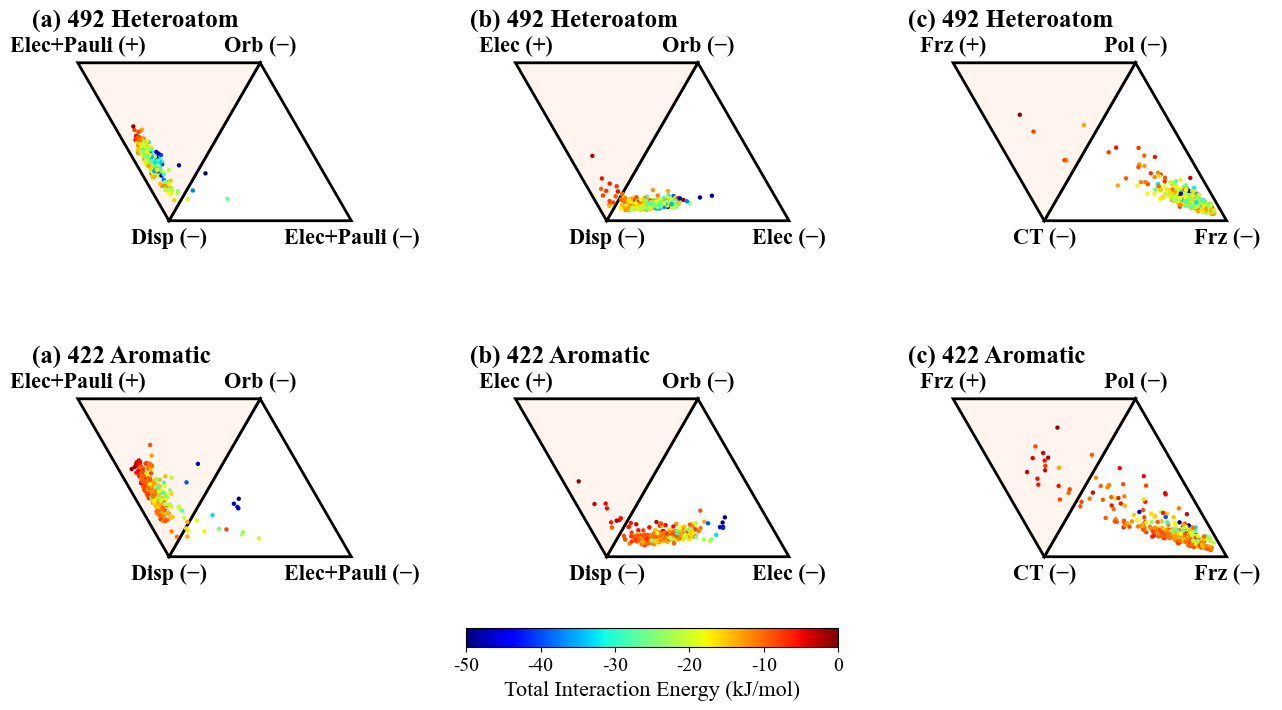

In [36]:
dfs = split_type(df)
cmap_range = [-50, 0]
type0 = 'frz_orb_disp'
type1 = 'elec_orb_disp'
type2 = 'frz_pol_ct'


fig, axes = plt.subplots(2, 3, figsize=(16, 10))
sc = plot('ternary', (labels[0], 'a', type0), dfs[0], axes[0, 0], cmap_range)
plot('ternary', (labels[0], 'b', type1), dfs[0], axes[0, 1], cmap_range)
plot('ternary', (labels[0], 'c', type2), dfs[0], axes[0, 2], cmap_range)
plot('ternary', (labels[1], 'a', type0), dfs[1], axes[1, 0], cmap_range)
plot('ternary', (labels[1], 'b', type1), dfs[1], axes[1, 1], cmap_range)
plot('ternary', (labels[1], 'c', type2), dfs[1], axes[1, 2], cmap_range)


cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary_T-P.png')


# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

In [39]:
dfs[1]

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,PAULI,DISP,CLS_ELEC,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL
3t19_231_TRP_3830-3843_12-17,3t19,3t19_5MA_A_561,pdbbind_opt_sm/,231,TRP,A,1,UNL,Z,3830 3831 3833 3834 3836 3837 3839 3841 3843,...,52.5544,-28.9570,-13.9443,31.6956,NaN,0.0,-11.2057,-2.5923,-3.7692,-17.5672
5lkr_757_TRP_11846-11859_2-7,5lkr,5lkr_6YC_B_611,pdbbind_opt_sm/,757,TRP,B,1,UNL,Z,11846 11847 11849 11850 11852 11853 11855 1185...,...,22.6151,-16.5400,-6.4349,13.6011,NaN,0.0,-9.3738,-1.3728,-1.9925,-12.7391
2oqi_629_TYR_10130-10139_7-27,2oqi,2oqi_GGO_B_901,pdbbind_opt_sm/,629,TYR,B,1,UNL,Z,10130 10131 10133 10135 10137 10139,...,22.4584,-15.3943,-3.3617,12.6243,NaN,0.0,-6.1318,-1.3696,-1.6053,-9.1066
3r6t_142_TRP_2266-2279_28-32,3r6t,3r6t_LU1_A_307,pdbbind_opt_sm/,142,TRP,A,1,UNL,Z,2266 2267 2269 2270 2272 2273 2275 2277 2279,...,80.3353,-36.6172,-13.3877,48.5810,NaN,0.0,-1.4239,-5.0354,-4.6434,-11.1027
4pg3_746_HIS_12207-12214_3-9,4pg3,4pg3_KRS_D_602,pdbbind_opt_sm/,746,HIS,D,1,UNL,Z,12207 12208 12210 12212 12214,...,48.7628,-21.0944,-11.9163,34.0894,NaN,0.0,1.0786,-2.2503,-4.1036,-5.2753
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4gjb_125_PHE_1915-1924_9-14,4gjb,4gjb_0ME_A_1001,pdbbind_opt_sm/,125,PHE,A,1,UNL,Z,1915 1916 1918 1920 1922 1924,...,31.6455,-18.8848,-6.7908,19.4558,NaN,-0.0,-6.2197,-1.4105,-2.5547,-10.1848
5ml3_90_TRP_1552-1562_21-26,5ml3,5ml3_DL3_B_201,pdbbind_opt_sm/,90,TRP,B,1,UNL,Z,1552 1555 1556 1558 1560 1562,...,47.1103,-28.5505,-9.0439,26.7766,NaN,0.0,-10.8178,-3.4204,-3.1852,-17.4234
6h12_119_TYR_1926-1935_15-46,6h12,6h12_FJK_B_619,pdbbind_opt_sm/,119,TYR,B,1,UNL,Z,1926 1927 1929 1931 1933 1935,...,124.7568,-29.9103,-32.3937,79.2661,NaN,0.0,16.9622,-12.8106,-12.8595,-8.7079
2vvu_206_TRP_3228-3241_5-10,2vvu,2vvu_H22_A_1244,pdbbind_opt_sm/,206,TRP,A,1,UNL,Z,3228 3229 3231 3232 3234 3235 3237 3239 3241,...,62.6091,-37.0425,-21.5136,39.8781,NaN,-0.0,-18.6780,-4.8547,-5.5210,-29.0537


len: list(map(len, dfs))
len: list(map(len, dfs))


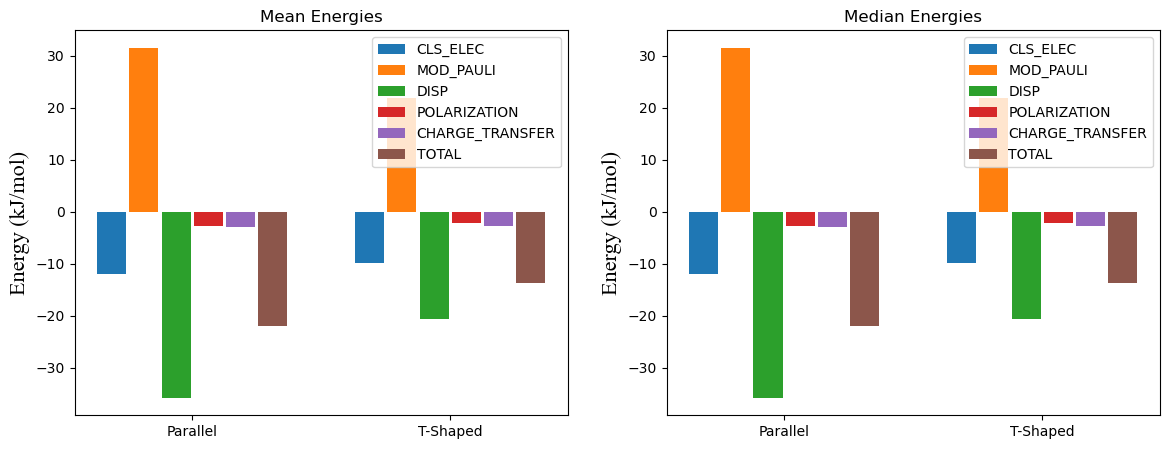

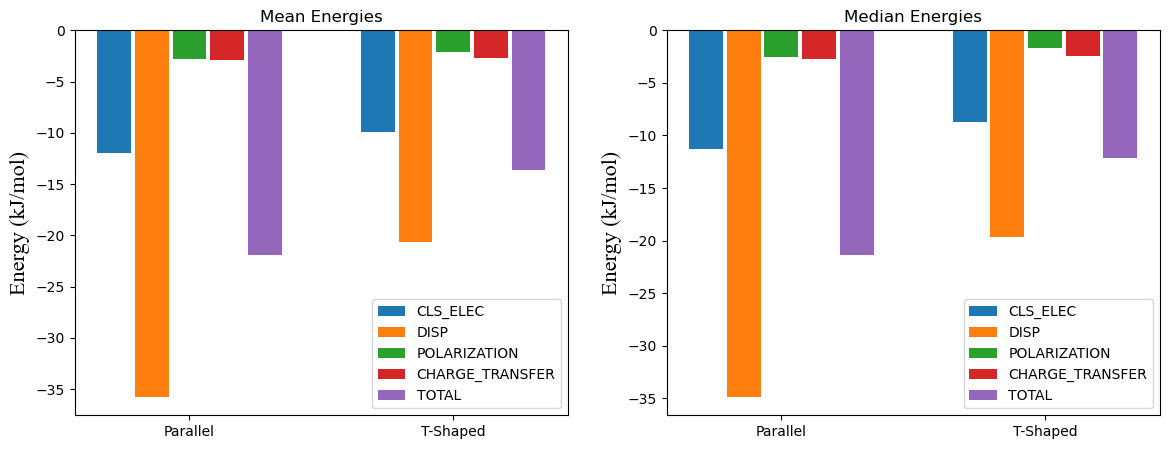

In [6]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_type(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_T-P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_type(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_T-P.png')

# Heteroatom vs Pure Aromatic comparison

## Protein Fragment Visualization + Processing

318
606


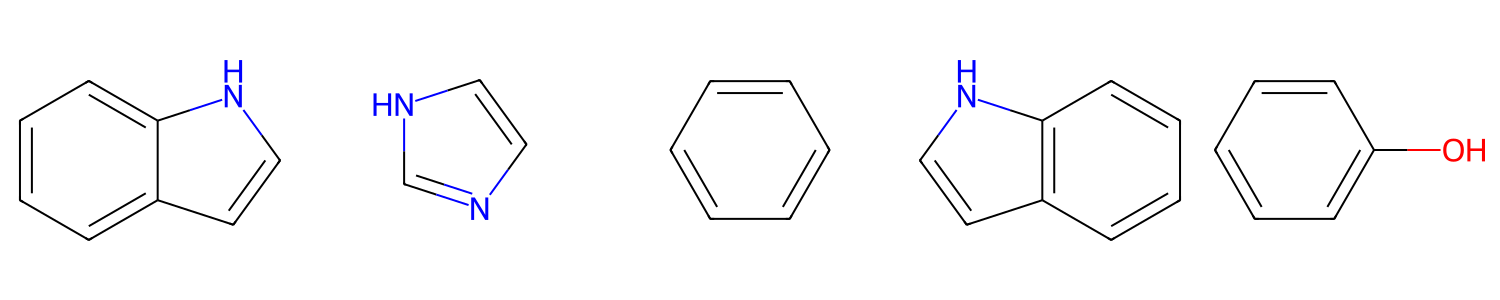

In [7]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

hetratom_prot = []
aromatic_prot = []

for index, row in df.iterrows():
    if row['restype'] == 'TYR' or row['restype'] == 'PHE':
        aromatic_prot.append(index)
    else:
        hetratom_prot.append(index)

print(len(hetratom_prot))
print(len(aromatic_prot))

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df['smiles1'])], subImgSize=(300, 300), molsPerRow=5)


## Ligand Fragment Visualization + Processing

In [8]:
# manually checking lignad types
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in df['smiles0'][:500]], legends=[f"{id1}\n{id2}" for id1, id2 in zip(df['PDBID'][:500], df['smiles0'][:500])], subImgSize=(300, 300), molsPerRow=7, maxMols=500)
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in df['smiles0'][500:]], legends=[id for id in df['PDBID'][500:]], subImgSize=(300, 300), molsPerRow=7, maxMols=500)

In [9]:
from edautils.fragment import find_rings_old

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
hetratom_lig = []
aromatic_lig = []

hetrato_atoms = []
aromatic_atoms = []

errs = []

for index, row in df.iterrows():
    aromatic = True
    temp_atomlist = []
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    ring_list = find_rings_old(mol, find_hetero_rings=False, find_small_rings=False) # only aromatic rings, idx numbers in OpenBabel 1 lower than Plip

    lig_idx_list = row['lig_idx_list'].split()
    lig_idx_set = set([int(id) - 1 for id in lig_idx_list])
    ring_temp = [s for s in ring_list if lig_idx_set & s]
    
    if row['PDBID'] == '3b2q': # Plip ring missidentification
        ring_temp = [21, 22, 23, 24, 25, 27, 28, 29, 30]
    elif row['PDBID'] == '2cm8': # reassign to aromatic ring
        ring_temp = [8, 9, 10, 11, 12, 13] 

    try:
        for idx in ring_temp[0]:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
            if not symbol == 'C':
                aromatic = False

        if aromatic:
            aromatic_lig.append(index)
            aromatic_atoms.append((index, temp_atomlist)) # keep the list of atoms
        else:
            hetratom_lig.append(index)
            hetrato_atoms.append((index, temp_atomlist)) # keep the list of atoms
    except Exception as e:
        for idx in lig_idx_set:
            atom = mol.GetAtomWithIdx(idx)
            symbol = atom.GetSymbol()
            temp_atomlist.append(symbol)
        errs.append([index, temp_atomlist])

print(len(aromatic_lig))
print(len(hetratom_lig))

errPDBID = [err[0] for err in errs]
errs

413
502


[['3wtm_186_TYR_2926-2935_7-14', ['N', 'C', 'N', 'C', 'C']],
 ['5oh7_166_TRP_2563-2573_2-6', ['C', 'C', 'N', 'N', 'C']],
 ['4bj8_212_TRP_3179-3192_11-16', ['C', 'N', 'C', 'N', 'C']],
 ['2ovh_99_PHE_1649-1658_11-17', ['C', 'C', 'C', 'C', 'C', 'C']],
 ['5oha_69_TRP_1065-1071_2-6', ['C', 'C', 'N', 'C', 'N']],
 ['2bgd_183_PHE_3049-3058_2-8', ['C', 'N', 'S', 'N', 'C']],
 ['3wth_55_TRP_896-906_9-13', ['N', 'C', 'C', 'N', 'C']],
 ['4dve_161_PHE_2469-2478_11-16', ['C', 'N', 'C', 'N', 'C']],
 ['2nta_182_PHE_3025-3034_8-17', ['N', 'N', 'C', 'C', 'S']]]

In [10]:
labels = ['Heteroatom', 'Aromatic', 'Hetero-Aromatic']

def split_hetr_aromatic(df, errPDBID):
    df0 = pd.DataFrame()
    df1 = pd.DataFrame()
    df2 = pd.DataFrame()

    for index, row in df.iterrows():
        if index in errPDBID:
            continue
        elif index in hetratom_prot and index in hetratom_lig:
            df0 = pd.concat([df0, row.to_frame().T])
        elif index in aromatic_lig and index in aromatic_lig:
            df1 = pd.concat([df1, row.to_frame().T])
        else:
            df2 = pd.concat([df2, row.to_frame().T])
    return [df0, df1, df2]

df_whole = split_hetr_aromatic(df,errPDBID)
df_P = split_hetr_aromatic(dfs[0], errPDBID)
df_T = split_hetr_aromatic(dfs[1], errPDBID)

In [32]:
df_whole[2]

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,prot_idx_list,...,PAULI,DISP,CLS_ELEC,MOD_PAULI,CLS_DISP,PREPARATION,FROZEN,POLARIZATION,CHARGE_TRANSFER,TOTAL
4pum_97_TYR_1504-1513_1-11,4pum,4pum_2WU_A_404,pdbbind_opt_sm/,97,TYR,A,1,UNL,Z,1504 1505 1507 1509 1511 1513,...,44.6199,-38.9591,-12.1187,24.1225,NaN,0.0,-26.9554,-3.4187,-2.2487,-32.6227
2wxf_637_TYR_10330-10339_24-28,2wxf,2wxf_039_A_1500,pdbbind_opt_sm/,637,TYR,A,1,UNL,Z,10330 10331 10333 10335 10337 10339,...,33.5173,-15.7281,-13.3324,22.1175,NaN,0.0,-6.943,-3.7092,-3.8209,-14.4731
5ddb_299_TYR_4732-4741_21-25,5ddb,5ddb_59Q_A_601,pdbbind_opt_sm/,299,TYR,A,1,UNL,Z,4732 4733 4735 4737 4739 4741,...,48.8724,-27.3526,-13.7408,28.008,NaN,-0.0,-13.0854,-2.2355,-2.7244,-18.0454
5o0j_269_PHE_4478-4487_14-24,5o0j,5o0j_8BR_A_502,pdbbind_opt_sm/,269,PHE,A,1,UNL,Z,4478 4479 4481 4483 4485 4487,...,87.5866,-51.5039,-21.3309,54.8238,NaN,0.0,-18.011,-3.1734,-4.3997,-25.5841
5hmh_50_TYR_906-915_14-37,5hmh,5hmh_62R_A_201,pdbbind_opt_sm/,50,TYR,A,1,UNL,Z,906 907 909 911 913 915,...,38.6354,-21.8839,-13.324,23.4275,NaN,0.0,-11.7805,-2.4393,-3.3244,-17.5442
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6mkw_14_TYR_214-223_6-10,6mkw,6mkw_HIS_A_301,pdbbind_opt_sm/,14,TYR,A,1,UNL,A,214 215 217 219 221 223,...,54.4622,-30.9771,-12.7533,31.5663,NaN,-0.0,-12.164,-2.6299,-2.6236,-17.4176
5hrx_32_PHE_552-561_2-7,5hrx,5hrx_64F_A_803,pdbbind_opt_sm/,32,PHE,A,1,UNL,Z,552 553 555 557 559 561,...,9.9691,-10.9917,-2.6601,5.2833,NaN,0.0,-8.3685,-0.477,-0.743,-9.5885
2r8q_295_PHE_4600-4609_1-9,2r8q,2r8q_IBM_A_3,pdbbind_opt_sm/,295,PHE,A,1,UNL,Z,4600 4601 4603 4605 4607 4609,...,35.2844,-33.5798,-8.619,19.3778,NaN,0.0,-22.821,-3.6181,-1.8108,-28.2499
2h42_287_PHE_4722-4731_8-14,2h42,2h42_VIA_C_903,pdbbind_opt_sm/,287,PHE,C,1,UNL,Z,4722 4723 4725 4727 4729 4731,...,68.4328,-45.176,-17.4891,42.1219,NaN,0.0,-20.5432,-2.3893,-4.0107,-26.9431


In [11]:
# print(dfs[0].shape)
# print(dfs[1].shape)
# print('\n')

# for df in df_whole:
#     print(df.shape)
# print('\n')

# for df in df_P:
#     print(df.shape)
# print('\n')

# for df in df_T:
#     print(df.shape)
# print('\n')

# Heteroatom vs Pure Aromatic Ternary

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_18265/3934735199.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


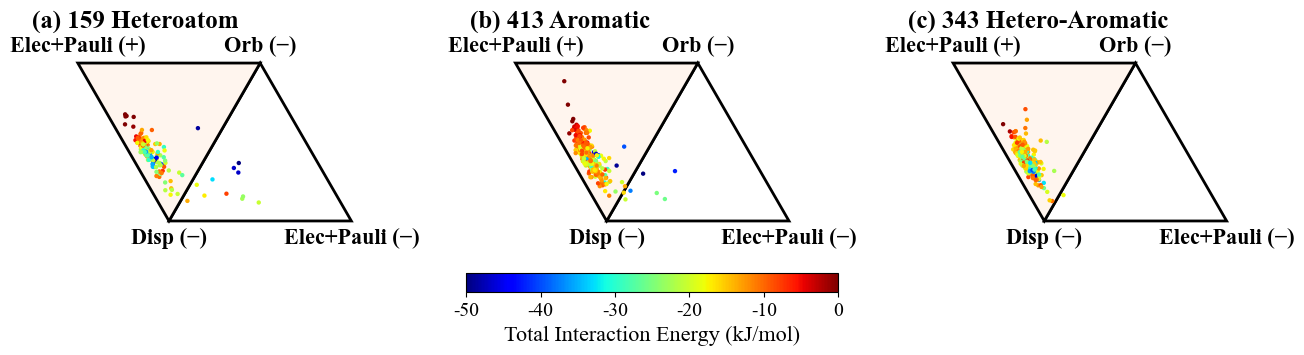

In [17]:
cmap_range = [-50, 0]
type = 'frz_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary_hetratm-aromatic_1.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_18265/4245040046.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


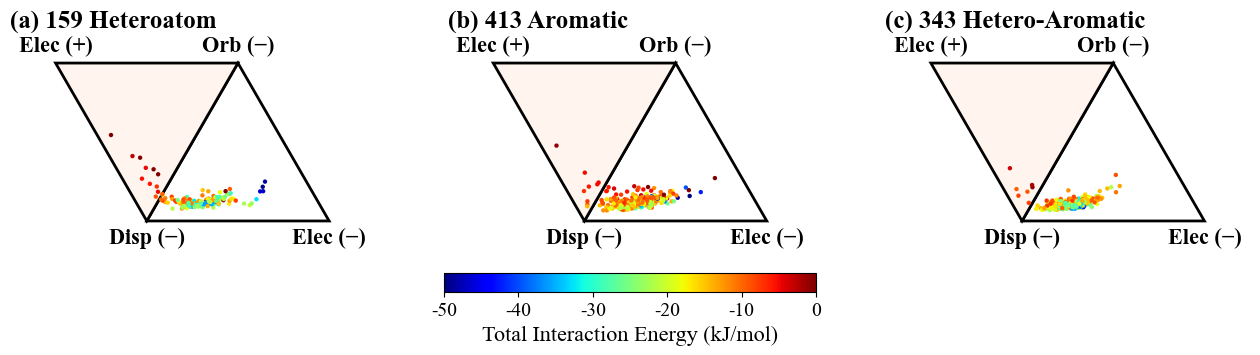

In [18]:
cmap_range = [-50, 0]
type = 'elec_orb_disp'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary_hetratm-aromatic_2.png')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_18265/3113725425.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


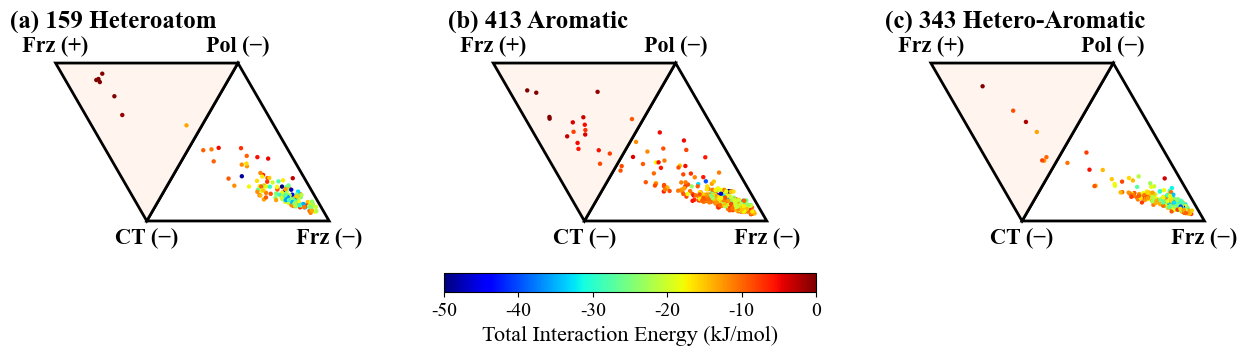

In [19]:
cmap_range = [-50, 0]
type = 'frz_pol_ct'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sc = plot('ternary', (labels[0], 'a', type), df_whole[0], axes[0], cmap_range)
plot('ternary', (labels[1], 'b', type), df_whole[1], axes[1], cmap_range)
plot('ternary', (labels[2], 'c', type), df_whole[2], axes[2], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

plt.savefig('Visualizations/ternary_hetratm-aromatic_3.png')

## Seperateing Parallel and T-Shaped

No difference

In [18]:
# cmap_range = [-50, 0]
# type = 'frz_orb_disp'

# fig, axes = plt.subplots(2, 3, figsize=(16, 10))
# sc = plot('ternary', (labels[0], 'a', type), df_P[0], axes[0, 0], cmap_range)
# plot('ternary', (labels[1], 'b', type), df_P[1], axes[0, 1], cmap_range)
# plot('ternary', (labels[2], 'c', type), df_P[2], axes[0, 2], cmap_range)
# plot('ternary', (labels[0], 'a', type), df_T[0], axes[1, 0], cmap_range)
# plot('ternary', (labels[1], 'b', type), df_T[1], axes[1, 1], cmap_range)
# plot('ternary', (labels[2], 'c', type), df_T[2], axes[1, 2], cmap_range)


# cbar = fig.colorbar(
#     sc, 
#     ax=axes, 
#     orientation='horizontal', 
#     shrink=0.3,
#     pad=0.05
# )
# cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
# cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

# plt.savefig('ternary_hetratm-aromatic_1.png')

# Heteroatom vs Pure Aromatic Bar Plot


## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: [159, 413, 343]
len: [492, 422]


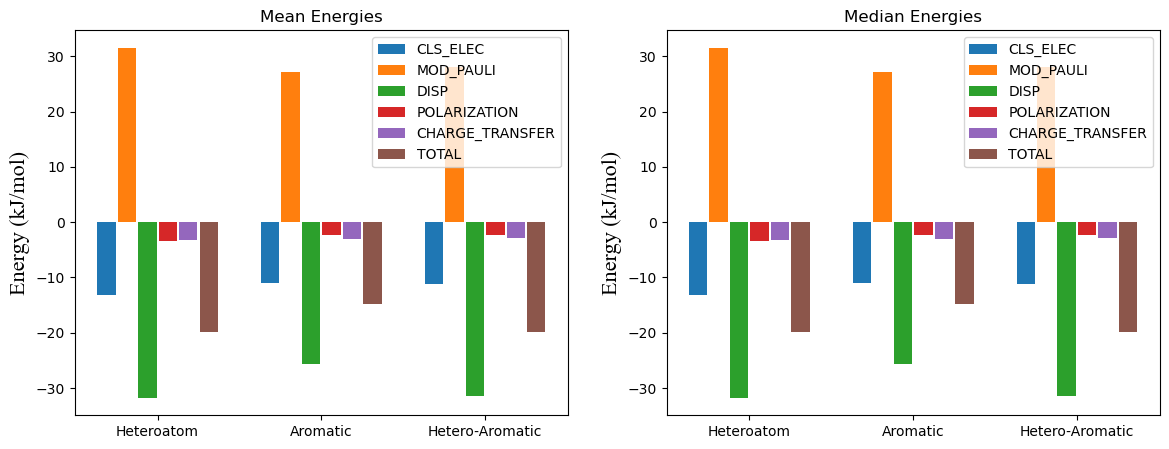

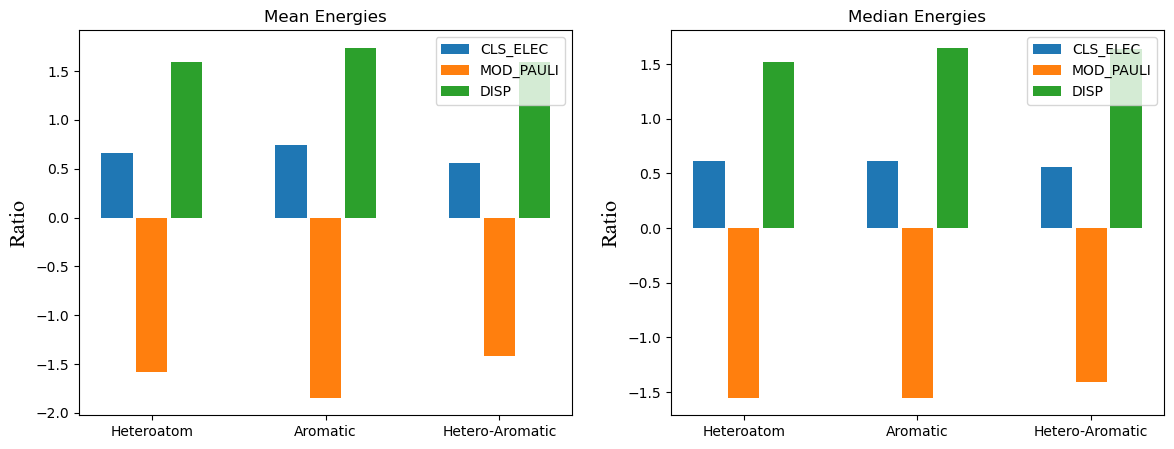

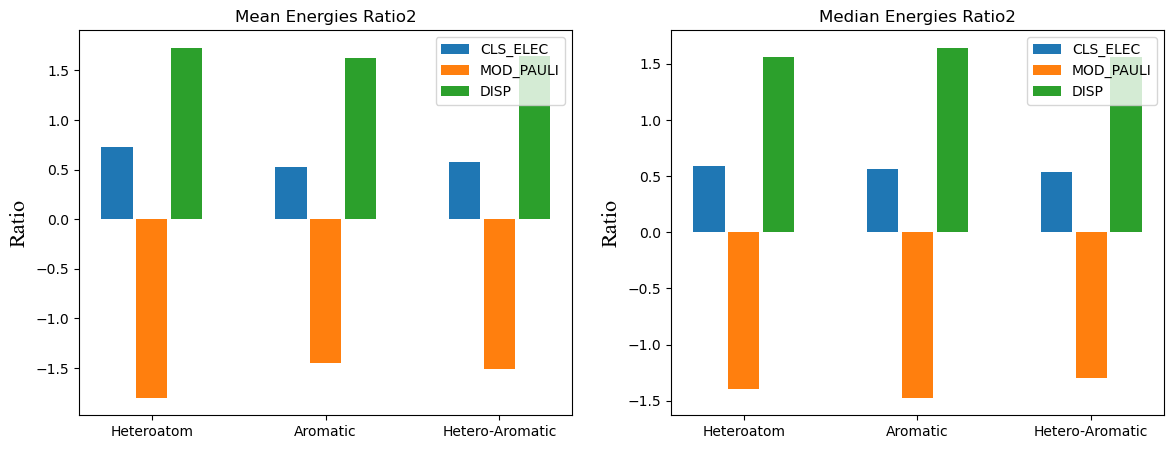

In [40]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_whole))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_whole, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_hetratom-aromatic.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    # 'POLARIZATION', 
    # 'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, dfs))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_whole, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_whole, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio2')
plot('bar', (labels, items), df_whole, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio2')
plt.savefig('Visualizations/bar_heteroatom_slides.png')

## Parallel Heteroatom Aromatic Split

len: [99, 153, 236]


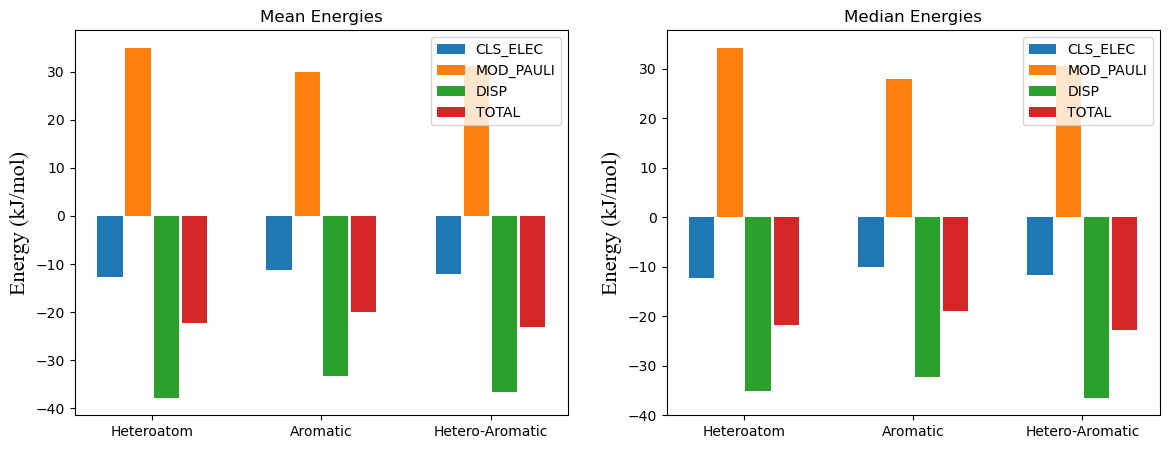

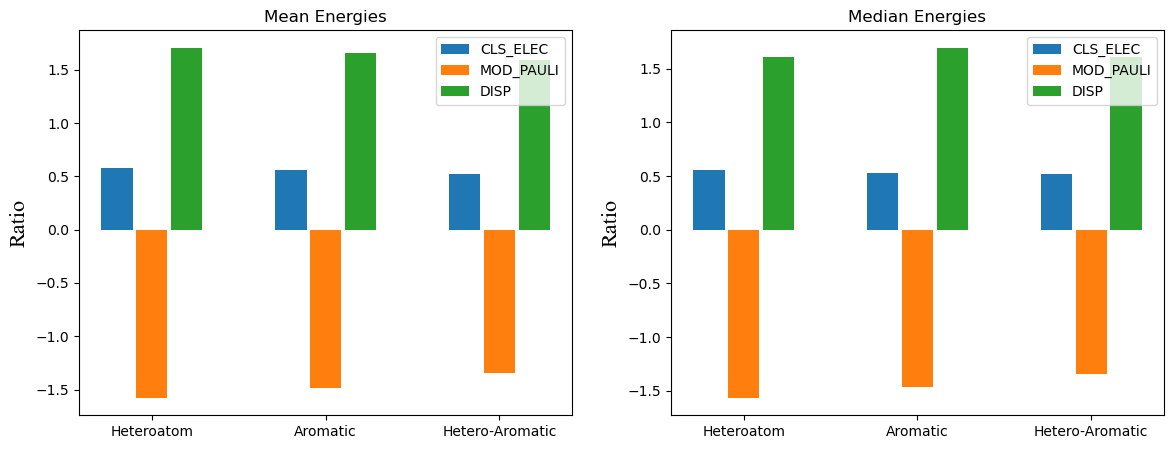

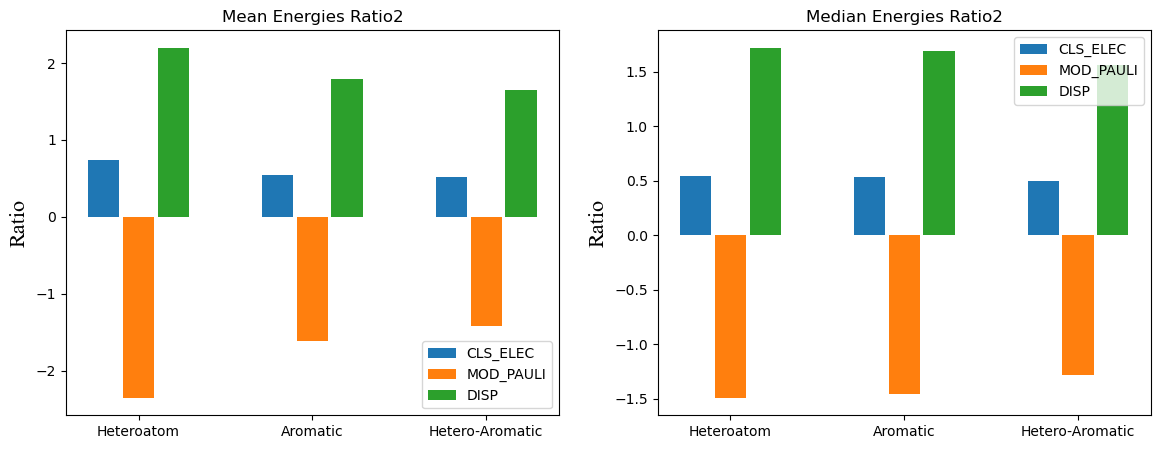

In [41]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    # 'POLARIZATION', 
    # 'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_P))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_P, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    # 'POLARIZATION', 
    # 'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_P, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_P, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio2')
plot('bar', (labels, items), df_P, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio2')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_P.png')

## T-Shaped Heteroatom split

len: [55, 256, 106]
len: [55, 256, 106]


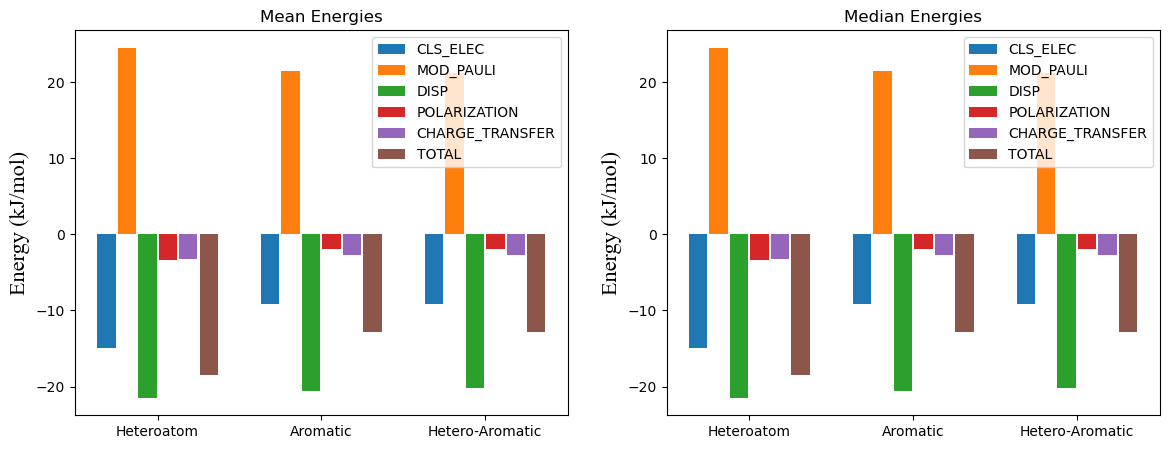

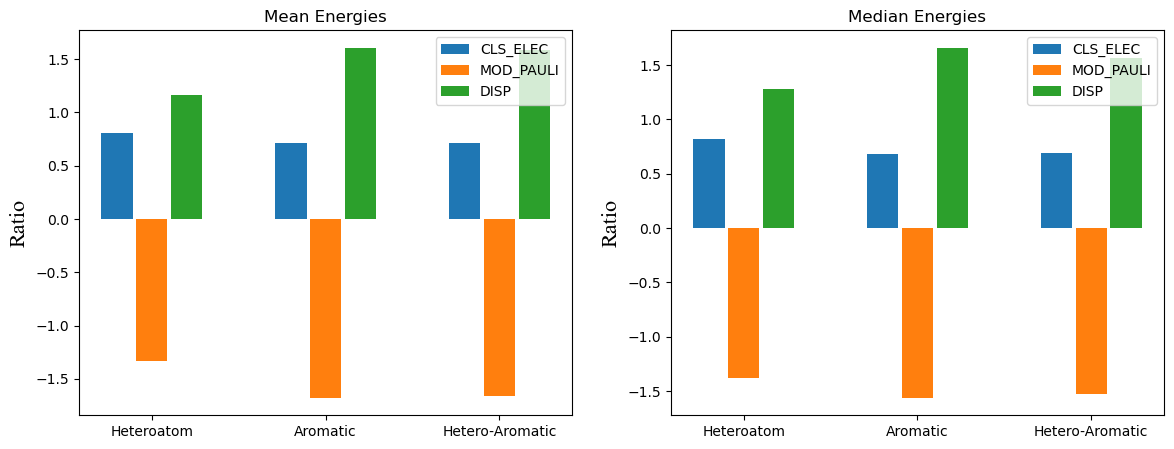

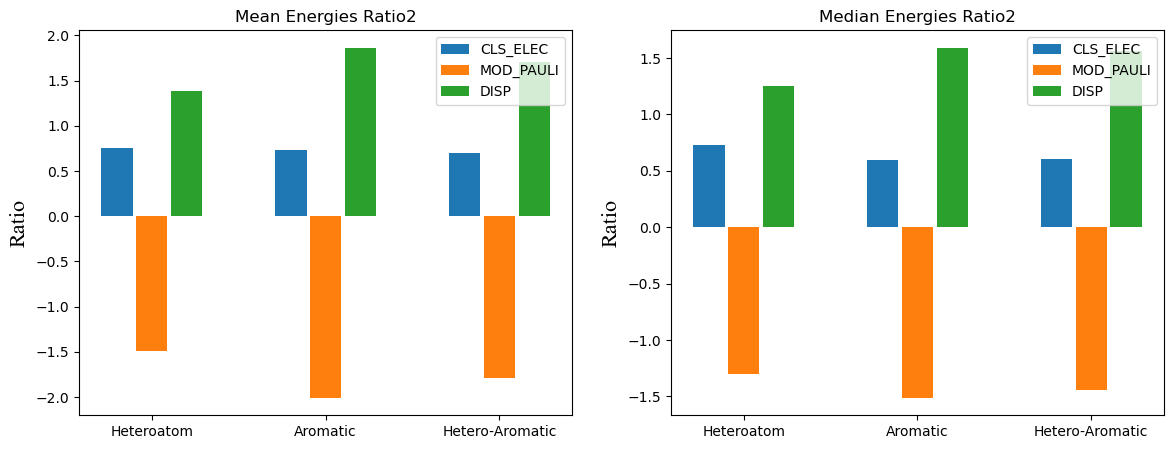

In [42]:
items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

print(f'len: {list(map(len, df_T))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_T, axes[1], median=False)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_all_hetratom-aromatic_T.png')

items = [
    # 'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    # 'POLARIZATION', 
    # 'CHARGE_TRANSFER', 
    # 'TOTAL'
]

print(f'len: {list(map(len, df_T))}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), df_T, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_T.png')


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), df_T, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio2')
plot('bar', (labels, items), df_T, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio2')
plt.savefig('Visualizations/bar_Energy_pauli+disp_hetratom-aromatic_T.png')